# Data exploration

Saved outputs show the original full experiment. The default execution mode is a small smoke check, not a reproduction of those scores.

In [ ]:
from pathlib import Path
import sys

ROOT = Path.cwd().resolve()
if not (ROOT / "data").is_dir():
    ROOT = ROOT.parent
if not (ROOT / "data/processed/cleaned_train.csv").is_file():
    raise FileNotFoundError("Open this notebook from the repository root or notebooks directory.")
sys.path.insert(0, str(ROOT / "src"))
OUTPUT = ROOT / "results/rerun"
OUTPUT.mkdir(parents=True, exist_ok=True)
SMOKE_TEST = True  # Small execution check. Set False explicitly for the historical search.


# Telecom churn: data exploration

Historical plots are preserved. Set `SMOKE_TEST=False` to include the large pairplot. See [research notes](../docs/research-notes.md).


In [25]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [26]:
#Load data
import pandas as pd
telcom = pd.read_csv(ROOT / 'data/raw/train.csv')
telcom.head()


,State,Account length,Area code,International plan,Voice mail plan,Number vmail messages,Total day minutes,Total day calls,Total day charge,Total eve minutes,Total eve calls,Total eve charge,Total night minutes,Total night calls,Total night charge,Total intl minutes,Total intl calls,Total intl charge,Customer service calls,Churn
0,KS,128,415,No,Yes,25,265.1,110,45.07,197.4,99,16.78,244.7,91,11.01,10.0,3,2.70,1,False
1,OH,107,415,No,Yes,26,161.6,123,27.47,195.5,103,16.62,254.4,103,11.45,13.7,3,3.70,1,False
2,NJ,137,415,No,No,0,243.4,114,41.38,121.2,110,10.30,162.6,104,7.32,12.2,5,3.29,0,False
3,OH,84,408,Yes,No,0,299.4,71,50.90,61.9,88,5.26,196.9,89,8.86,6.6,7,1.78,2,False
4,OK,75,415,Yes,No,0,166.7,113,28.34,148.3,122,12.61,186.9,121,8.41,10.1,3,2.73,3,False


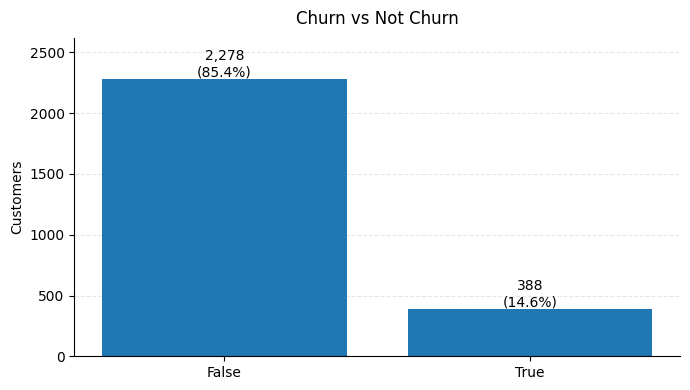

In [27]:
# Count churn vs not churn
counts = telcom["Churn"].value_counts(dropna=False)

# Ensure a consistent order if your labels are Yes/No
order = [x for x in ["True", "False"] if x in counts.index] + [x for x in counts.index if x not in ["False", "True"]]
counts = counts.reindex(order)

total = counts.sum()
perc = (counts / total * 100).round(1)

fig, ax = plt.subplots(figsize=(7, 4))

bars = ax.bar(counts.index.astype(str), counts.values)

ax.set_title("Churn vs Not Churn", pad=10)
ax.set_xlabel("")
ax.set_ylabel("Customers")

# Add labels (count + %)
y_max = counts.max()
ax.set_ylim(0, y_max * 1.15)

for bar, c, p in zip(bars, counts.values, perc.values):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{c:,}\n({p}%)",
        ha="center",
        va="bottom"
    )

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


In [28]:
def dataoveriew(df, message):
    print(f'{message}:\n')
    print("Rows:", df.shape[0])
    print("\nNumber of features:", df.shape[1])
    print("\nFeatures:")
    print(df.columns.tolist())
    print("\nMissing values:", df.isnull().sum().values.sum())
    print("\nUnique values:")
    print(df.nunique())
dataoveriew(telcom, 'Overiew of the training dataset')


Overiew of the training dataset:

Rows: 2666

Number of features: 20

Features:
['State', 'Account length', 'Area code', 'International plan', 'Voice mail plan', 'Number vmail messages', 'Total day minutes', 'Total day calls', 'Total day charge', 'Total eve minutes', 'Total eve calls', 'Total eve charge', 'Total night minutes', 'Total night calls', 'Total night charge', 'Total intl minutes', 'Total intl calls', 'Total intl charge', 'Customer service calls', 'Churn']

Missing values: 0

Unique values:
State                       51
Account length             205
Area code                    3
International plan           2
Voice mail plan              2
Number vmail messages       42
Total day minutes         1489
Total day calls            115
Total day charge          1489
Total eve minutes         1442
Total eve calls            120
Total eve charge          1301
Total night minutes       1444
Total night calls          118
Total night charge         885
Total intl minutes         15

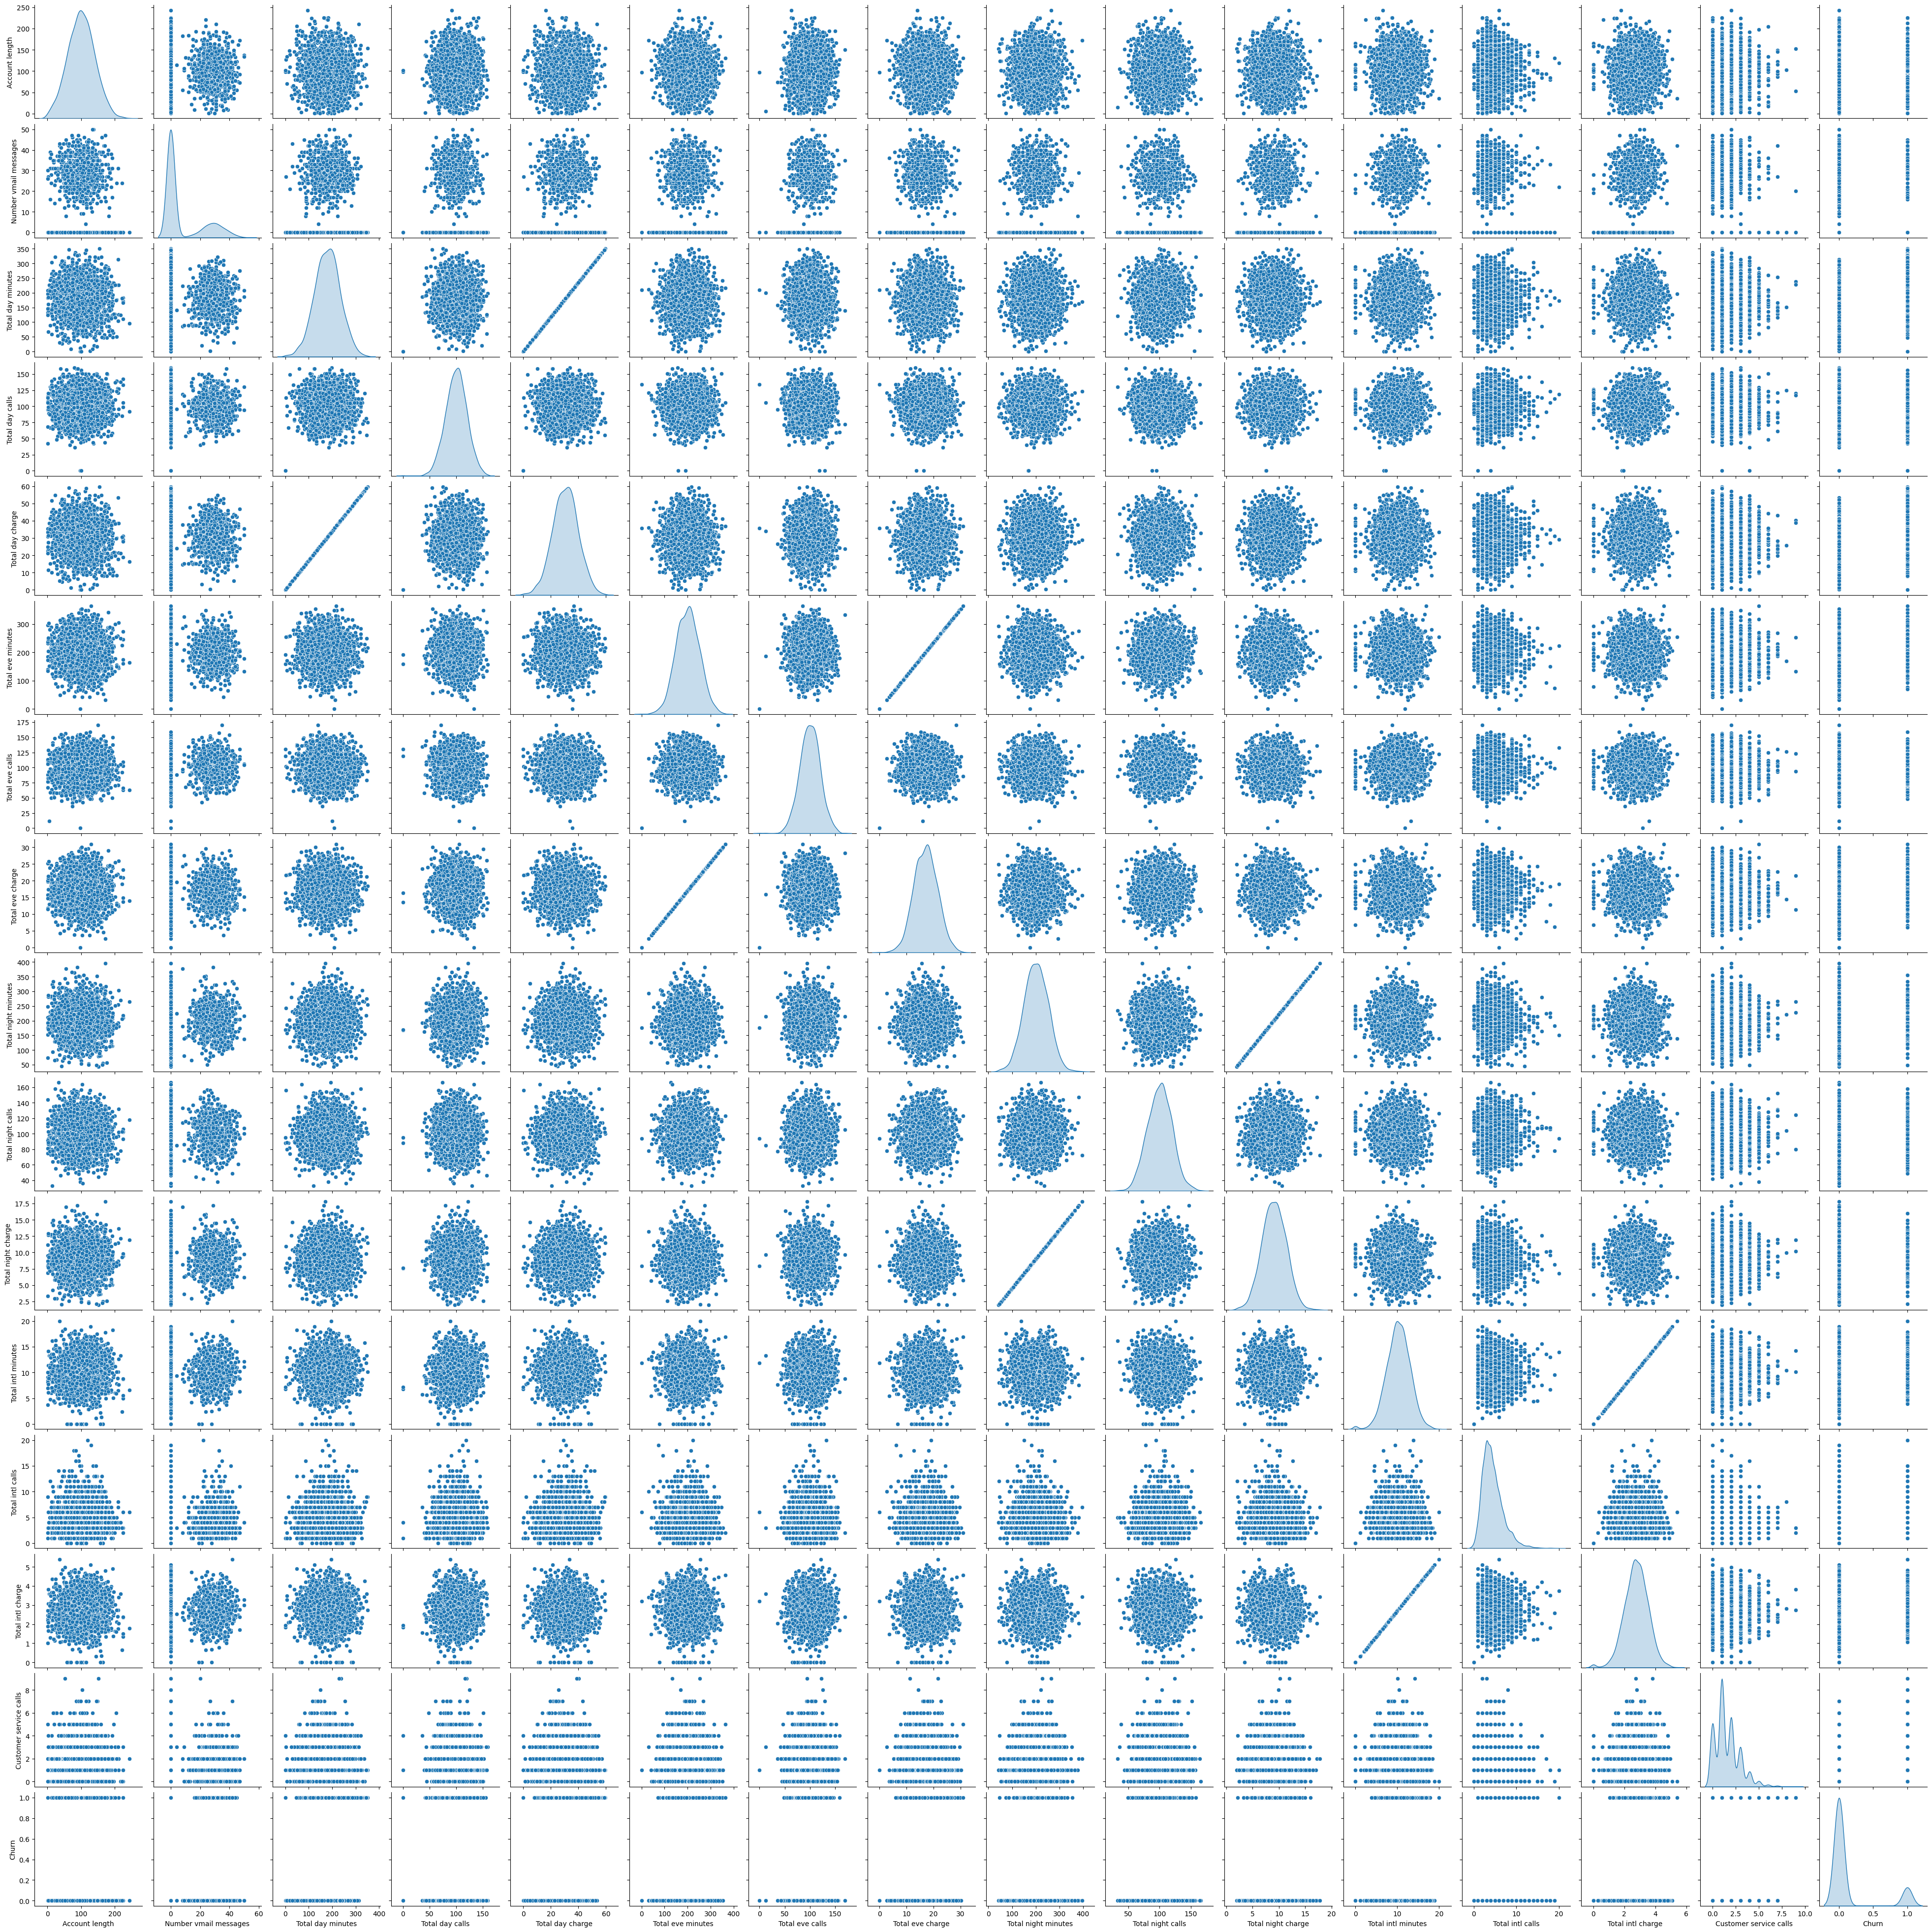

In [29]:
#Separating columns to be visualized
out_cols = list(set(telcom.nunique()[telcom.nunique()<6].keys().tolist()
                    + telcom.select_dtypes(include=['object', 'string']).columns.tolist()))
viz_cols = [x for x in telcom.columns if x not in out_cols] + ['Churn']

if not SMOKE_TEST:
    sns.pairplot(telcom[viz_cols], diag_kind="kde")
plt.show()


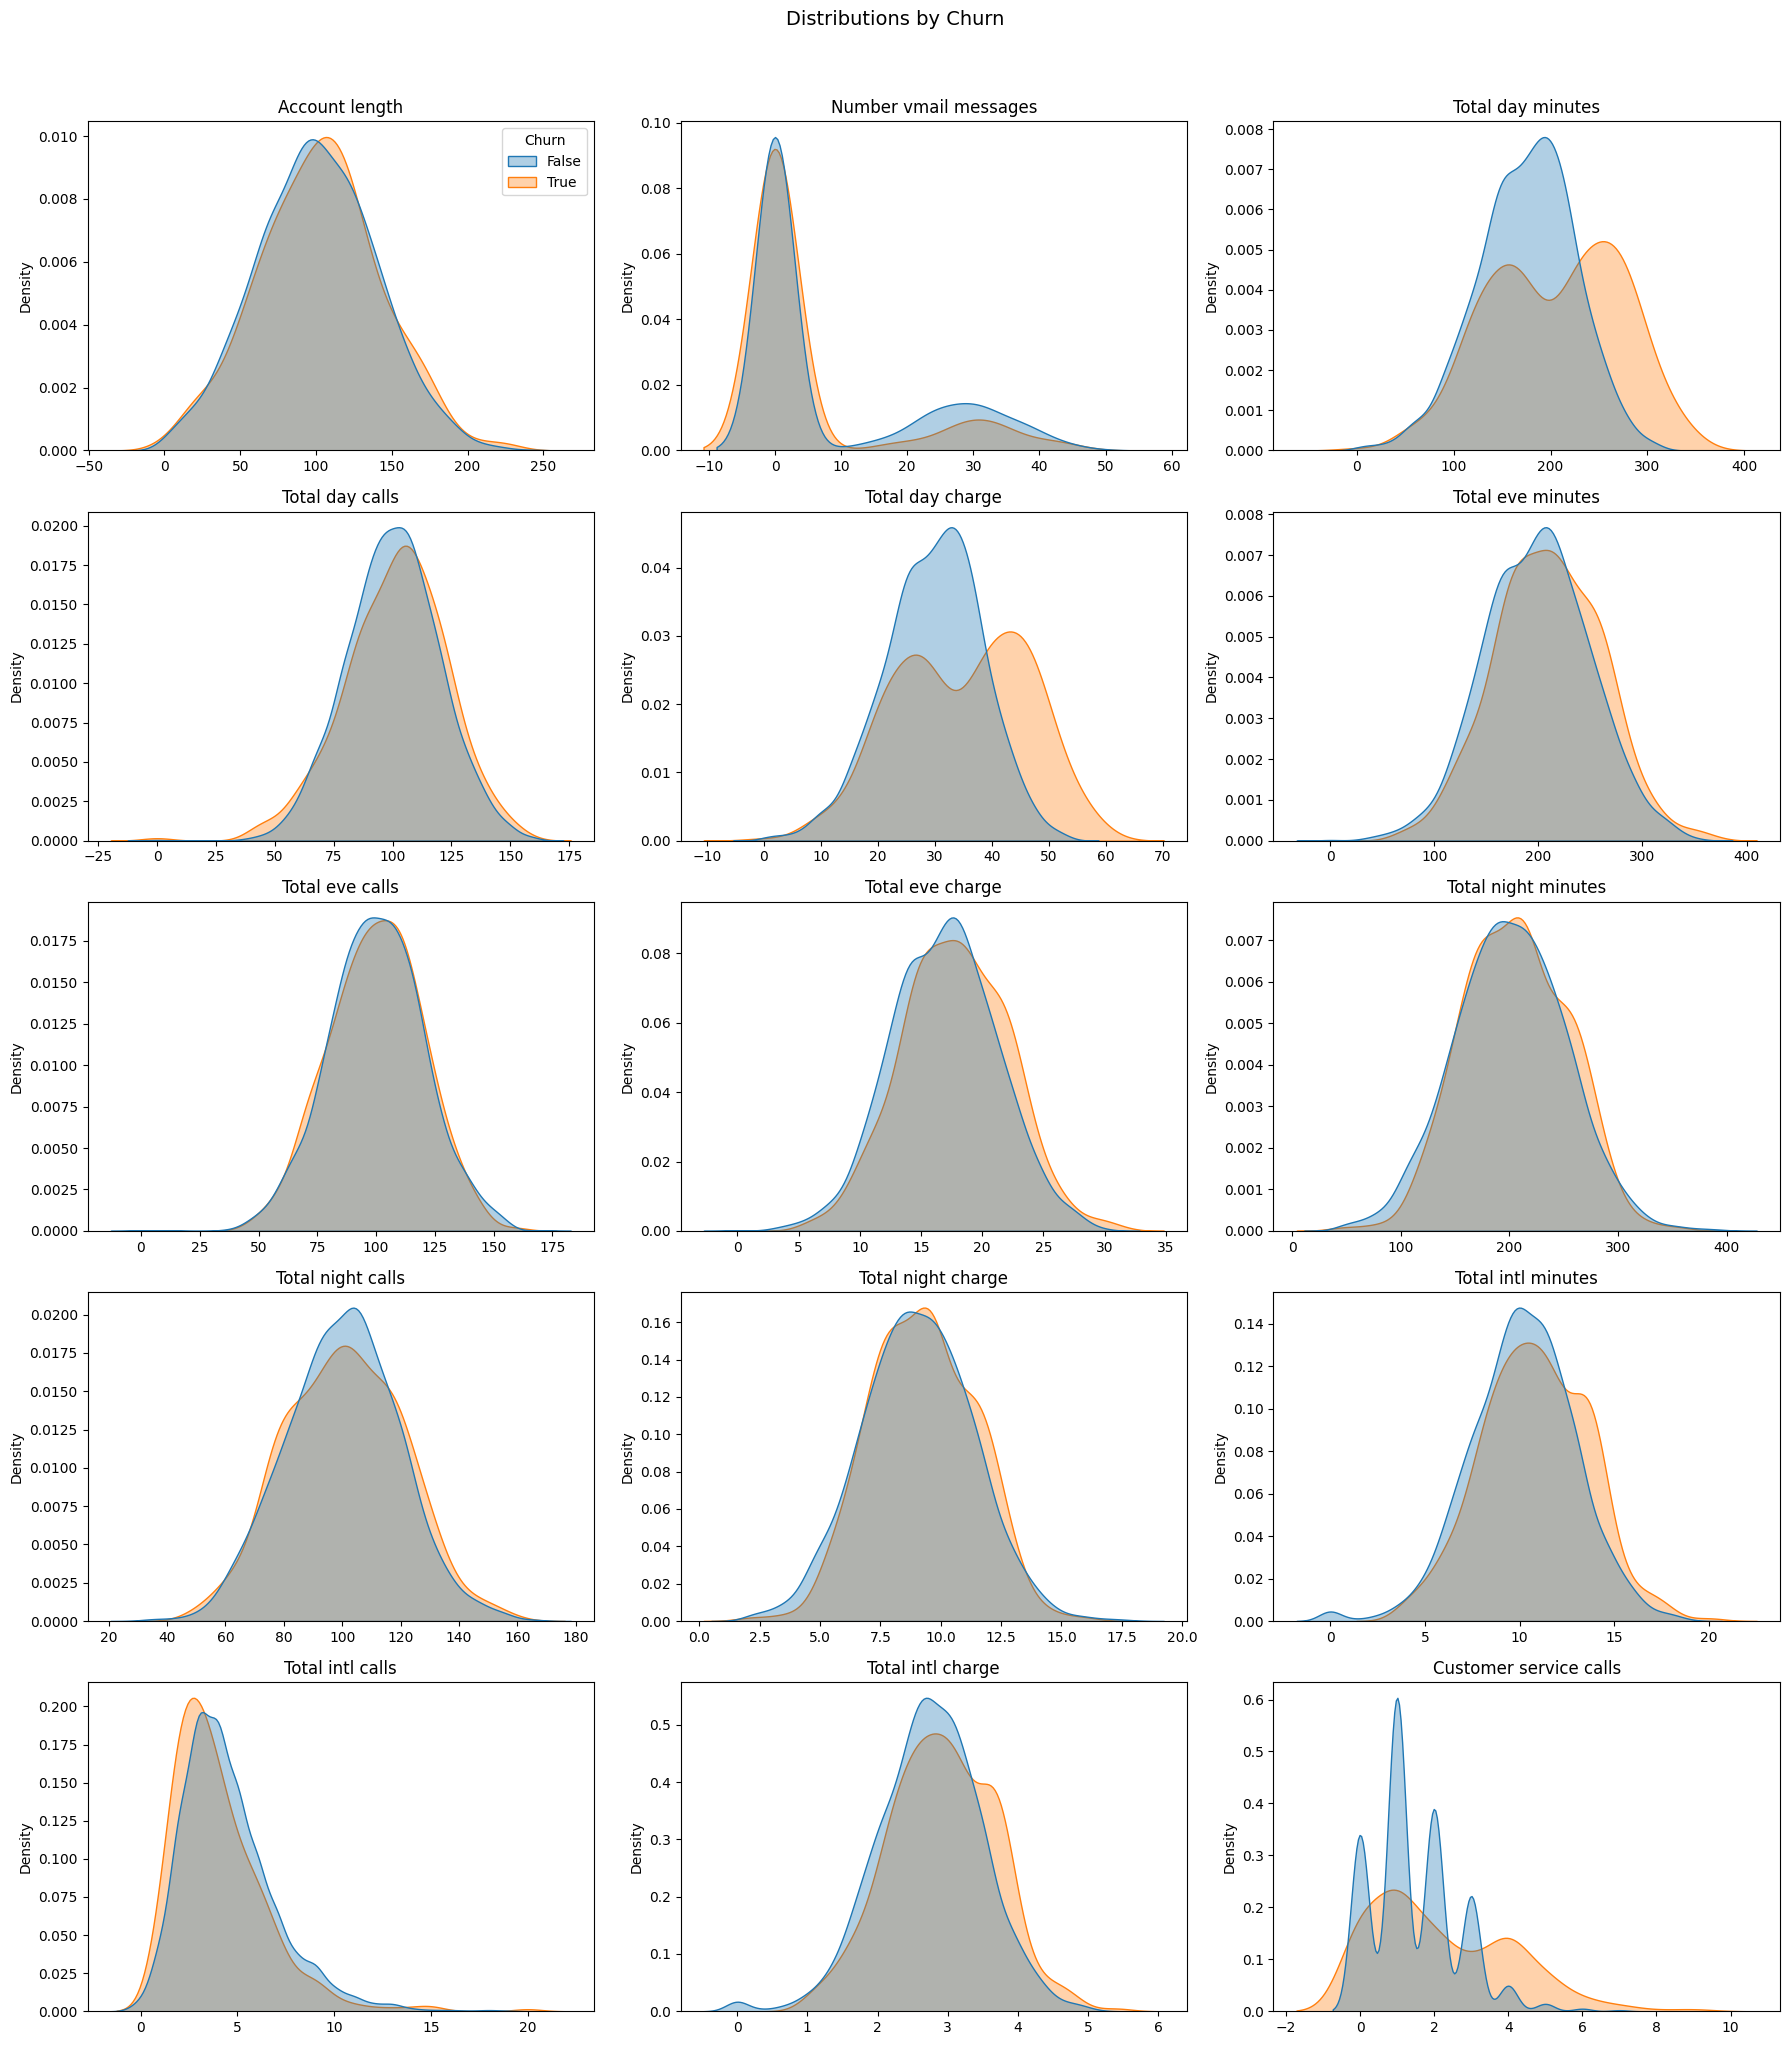

In [30]:
import math
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt



# --- pick the churn column that exists ---
if "Churn" in telcom.columns:
    churn_col = "Churn"
elif "Churn_Yes" in telcom.columns:
    churn_col = "Churn_Yes"
else:
    matches = [c for c in telcom.columns if "churn" in c.lower()]
    if not matches:
        raise KeyError("No Churn column found (expected 'Churn' or 'Churn_Yes').")
    churn_col = matches[0]

# --- choose columns to plot (exclude churn itself, keep existing cols) ---
plot_cols = [c for c in viz_cols if c in telcom.columns and c != churn_col]

# If this is huge, the figure will be unreadable; optionally cap it:
# plot_cols = plot_cols[:12]

# --- layout ---
n = len(plot_cols)
ncols = 3
nrows = math.ceil(n / ncols)

fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 6, nrows * 4))
axes = axes.flatten()

for i, col in enumerate(plot_cols):
    ax = axes[i]

    # numeric -> KDE
    if pd.api.types.is_numeric_dtype(telcom[col]):
        sns.kdeplot(
            data=telcom,
            x=col,
            hue=churn_col,
            common_norm=False,
            fill=True,
            alpha=0.35,
            ax=ax
        )
        ax.set_ylabel("Density")

    # non-numeric -> countplot
    else:
        sns.countplot(data=telcom, x=col, hue=churn_col, ax=ax)
        ax.set_ylabel("Count")
        ax.tick_params(axis="x", rotation=30)

    ax.set_title(col)
    ax.set_xlabel("")

    # avoid repeating the legend in every subplot
    if i != 0 and ax.get_legend() is not None:
        ax.get_legend().remove()

# turn off unused axes
for j in range(i + 1, len(axes)):
    axes[j].axis("off")

fig.suptitle(f"Distributions by {churn_col}", y=1.02, fontsize=14)
plt.tight_layout()
plt.show()


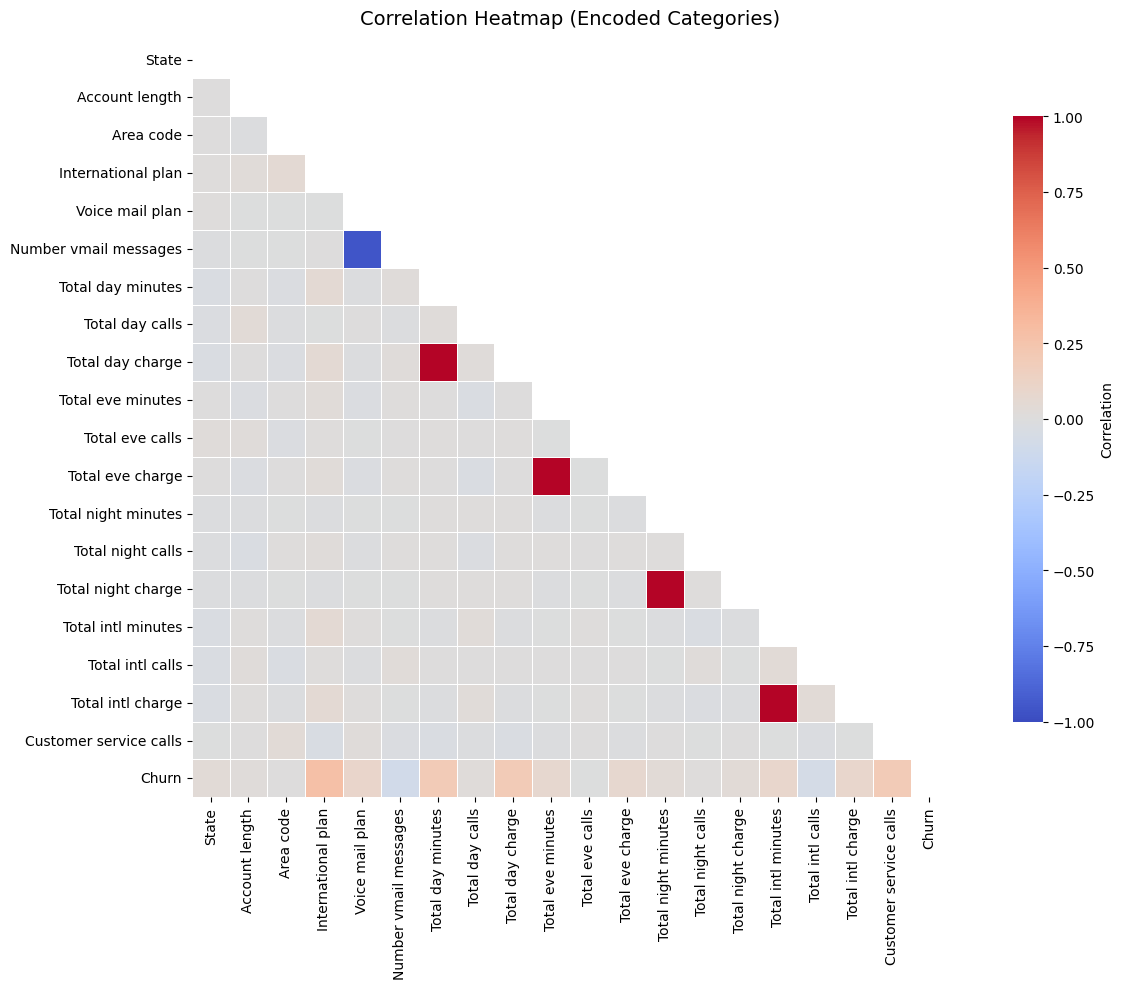

In [31]:
# --- 1) Create an encoded copy for correlation only (do not overwrite telcom) ---
corr_df = telcom.copy()

cat_cols = corr_df.select_dtypes(include=["object", "string", "category", "bool"]).columns
for col in cat_cols:
    corr_df[col] = pd.factorize(corr_df[col])[0]

# --- 2) Compute correlation (numeric-only after encoding) ---
corr = corr_df.corr(numeric_only=True)

# --- 3) Build a clean heatmap (upper triangle, optional selective annotations) ---
mask = np.triu(np.ones_like(corr, dtype=bool))

plt.figure(figsize=(14, 10))

ax = sns.heatmap(
    corr,
    mask=mask,
    cmap="coolwarm",
    vmin=-1, vmax=1,
    center=0,
    square=True,
    linewidths=0.5,
    cbar_kws={"shrink": 0.8, "label": "Correlation"}
)

plt.title("Correlation Heatmap (Encoded Categories)", fontsize=14, pad=12)
plt.tight_layout()
plt.show()


In [48]:
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler
df_train = pd.read_csv(ROOT / 'data/raw/train.csv')
df_test = pd.read_csv(ROOT / 'data/raw/test.csv')
#charge and minites are highly correlated, thus dropping the charges
df_train = df_train.drop(['Total intl charge', 'Total eve charge','Total day charge','Total night charge'], axis=1)
df_test = df_test.drop(['Total intl charge', 'Total eve charge','Total day charge','Total night charge'], axis=1)
print(df_train.info())
#dummy variables for categorical variables with more than 2 categories


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2666 entries, 0 to 2665
Data columns (total 16 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   State                   2666 non-null   object 
 1   Account length          2666 non-null   int64  
 2   Area code               2666 non-null   int64  
 3   International plan      2666 non-null   object 
 4   Voice mail plan         2666 non-null   object 
 5   Number vmail messages   2666 non-null   int64  
 6   Total day minutes       2666 non-null   float64
 7   Total day calls         2666 non-null   int64  
 8   Total eve minutes       2666 non-null   float64
 9   Total eve calls         2666 non-null   int64  
 10  Total night minutes     2666 non-null   float64
 11  Total night calls       2666 non-null   int64  
 12  Total intl minutes      2666 non-null   float64
 13  Total intl calls        2666 non-null   int64  
 14  Customer service calls  2666 non-null   

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import OrdinalEncoder, StandardScaler

cat_cols = df_train.select_dtypes(include=["object", "string"]).columns.tolist()
enc = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)

df_train[cat_cols] = enc.fit_transform(df_train[cat_cols])  
df_test[cat_cols]  = enc.transform(df_test[cat_cols])       

df_train["Churn"] = df_train["Churn"].astype(int)
df_test["Churn"]  = df_test["Churn"].astype(int)  # only if present/needed

#Standardize numerical features
num_cols = df_train.select_dtypes(include=["int64", "float64"]).columns.tolist()
#move target column from num_cols
num_cols.remove("Churn")
scaler = StandardScaler()
df_train[num_cols] = scaler.fit_transform(df_train[num_cols])  
df_test[num_cols]  = scaler.transform(df_test[num_cols])       

print(df_train.head())
print(df_test.head())


      State  Account length  Area code  International plan  Voice mail plan  \
0 -0.672700        0.692163  -0.527811           -0.335690         1.623917   
1  0.600844        0.161278  -0.527811           -0.335690         1.623917   
2  0.332730        0.919686  -0.527811           -0.335690        -0.615795   
3  0.600844       -0.420168  -0.692467            2.978938        -0.615795   
4  0.667873       -0.647691  -0.527811            2.978938        -0.615795   

   Number vmail messages  Total day minutes  Total day calls  \
0               1.247508           1.579670         0.484868   
1               1.320985          -0.329918         1.135375   
2              -0.589414           1.179302         0.685024   
3              -0.589414           2.212509        -1.466653   
4              -0.589414          -0.235822         0.634985   

   Total eve minutes  Total eve calls  Total night minutes  Total night calls  \
0          -0.058619        -0.050781             0.857403 

In [50]:
import numpy as np
import pandas as pd

# Build summary (like your code)
summary = (
    df_train
    .describe(include="all")          # use include="all" if you want non-numeric too
    .T
    .reset_index()
    .rename(columns={"index": "feature"})
)

summary = summary.round(3)

# Display (Jupyter will render as a table automatically)
summary


,feature,count,mean,std,min,25%,50%,75%,max
0,State,2666.0,0.000,1.000,-1.745,-0.874,-0.002,0.869,1.606
1,Account length,2666.0,-0.000,1.000,-2.518,-0.698,-0.016,0.667,3.599
2,Area code,2666.0,-0.000,1.000,-0.692,-0.692,-0.528,1.707,1.707
3,International plan,2666.0,-0.000,1.000,-0.336,-0.336,-0.336,-0.336,2.979
4,Voice mail plan,2666.0,0.000,1.000,-0.616,-0.616,-0.616,1.624,1.624
5,Number vmail messages,2666.0,-0.000,1.000,-0.589,-0.589,-0.589,0.807,3.084
6,Total day minutes,2666.0,0.000,1.000,-3.311,-0.666,0.009,0.672,3.161
7,Total day calls,2666.0,0.000,1.000,-5.019,-0.666,0.035,0.685,2.987
8,Total eve minutes,2666.0,-0.000,1.000,-3.934,-0.689,0.010,0.681,3.206
9,Total eve calls,2666.0,0.000,1.000,-4.962,-0.646,-0.001,0.693,3.471


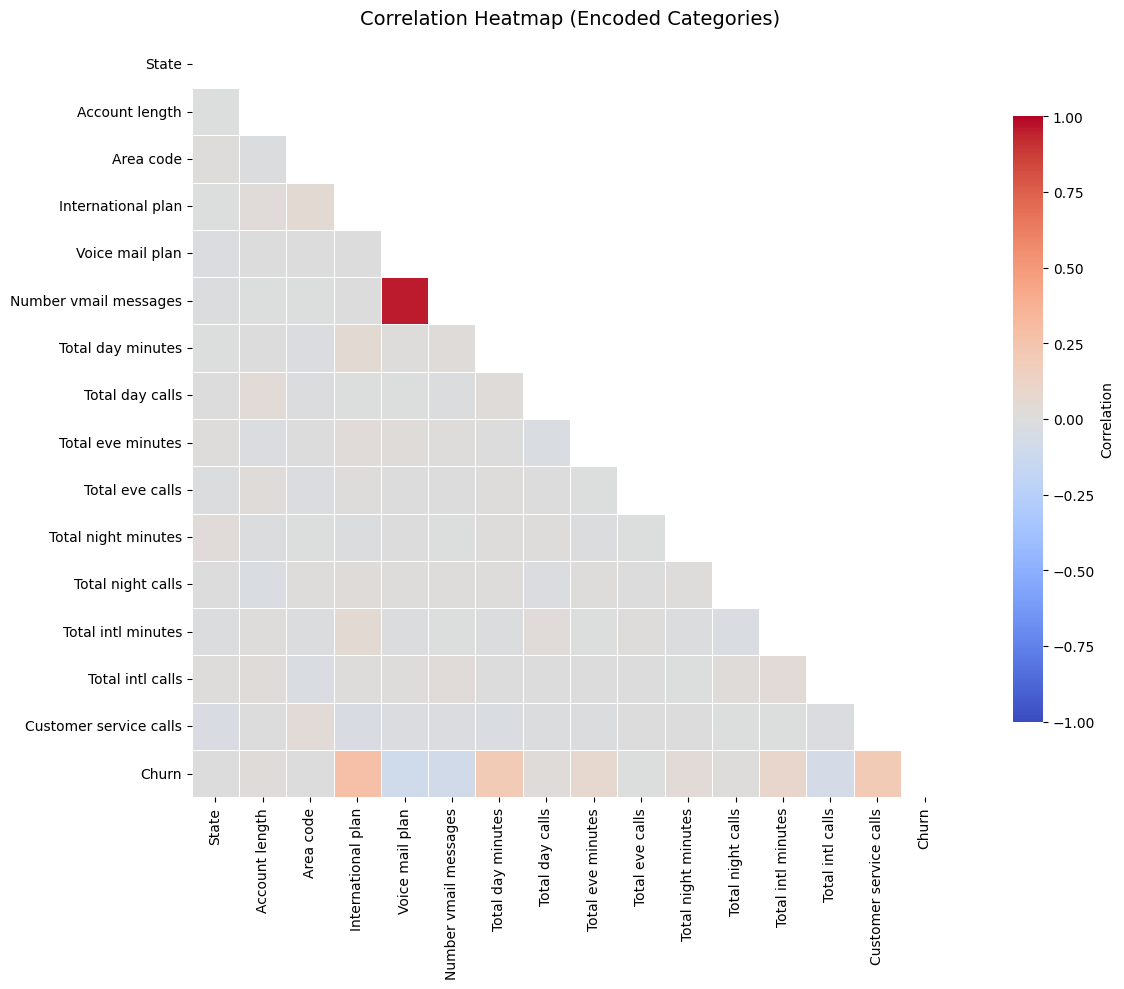

In [51]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
# --- 1) Create an encoded copy for correlation only (do not overwrite telcom) ---
corr_df = df_train.copy()
# --- 2) Compute correlation (numeric-only after encoding) ---
corr = corr_df.corr(numeric_only=True)

# --- 3) Build a clean heatmap (upper triangle, optional selective annotations) ---
mask = np.triu(np.ones_like(corr, dtype=bool))

plt.figure(figsize=(14, 10))

ax = sns.heatmap(
    corr,
    mask=mask,
    cmap="coolwarm",
    vmin=-1, vmax=1,
    center=0,
    square=True,
    linewidths=0.5,
    cbar_kws={"shrink": 0.8, "label": "Correlation"}
)

plt.title("Correlation Heatmap (Encoded Categories)", fontsize=14, pad=12)
plt.tight_layout()
plt.show()


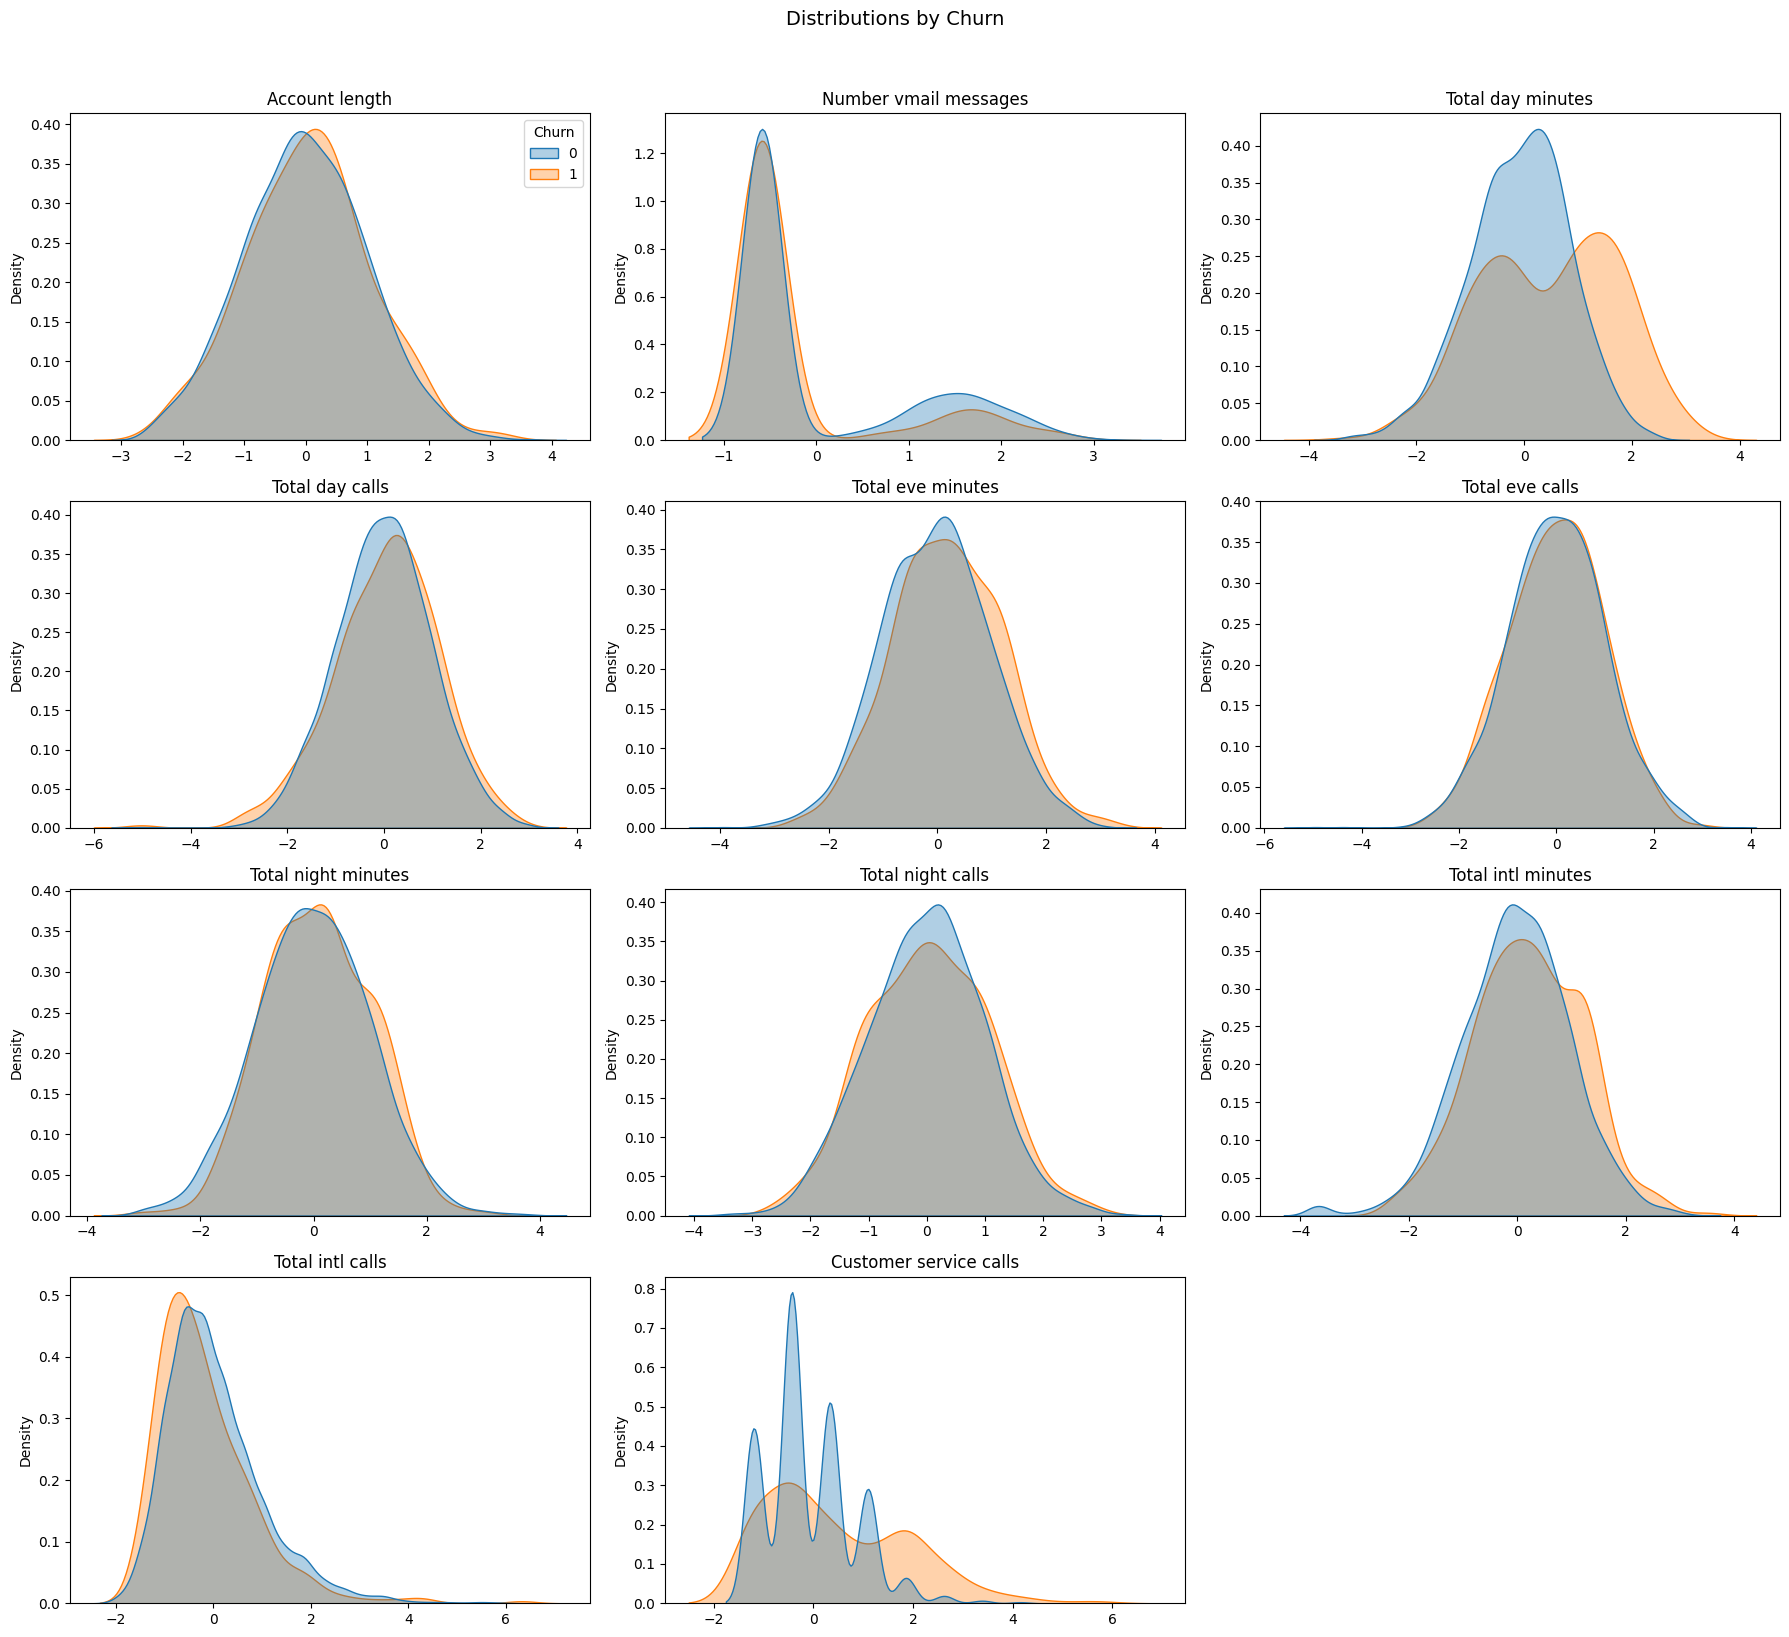

In [52]:
import math
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt



# --- pick the churn column that exists ---
if "Churn" in df_train.columns:
    churn_col = "Churn"
elif "Churn_Yes" in df_train.columns:
    churn_col = "Churn_Yes"
else:
    matches = [c for c in df_train.columns if "churn" in c.lower()]
    if not matches:
        raise KeyError("No Churn column found (expected 'Churn' or 'Churn_Yes').")
    churn_col = matches[0]

# --- choose columns to plot (exclude churn itself, keep existing cols) ---
plot_cols = [c for c in viz_cols if c in df_train.columns and c != churn_col]

# If this is huge, the figure will be unreadable; optionally cap it:
# plot_cols = plot_cols[:12]

# --- layout ---
n = len(plot_cols)
ncols = 3
nrows = math.ceil(n / ncols)

fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 6, nrows * 4))
axes = axes.flatten()

for i, col in enumerate(plot_cols):
    ax = axes[i]

    # numeric -> KDE
    if pd.api.types.is_numeric_dtype(df_train[col]):
        sns.kdeplot(
            data=df_train,
            x=col,
            hue=churn_col,
            common_norm=False,
            fill=True,
            alpha=0.35,
            ax=ax
        )
        ax.set_ylabel("Density")

    # non-numeric -> countplot
    else:
        sns.countplot(data=df_train, x=col, hue=churn_col, ax=ax)
        ax.set_ylabel("Count")
        ax.tick_params(axis="x", rotation=30)

    ax.set_title(col)
    ax.set_xlabel("")

    # avoid repeating the legend in every subplot
    if i != 0 and ax.get_legend() is not None:
        ax.get_legend().remove()

# turn off unused axes
for j in range(i + 1, len(axes)):
    axes[j].axis("off")

fig.suptitle(f"Distributions by {churn_col}", y=1.02, fontsize=14)
plt.tight_layout()
plt.show()


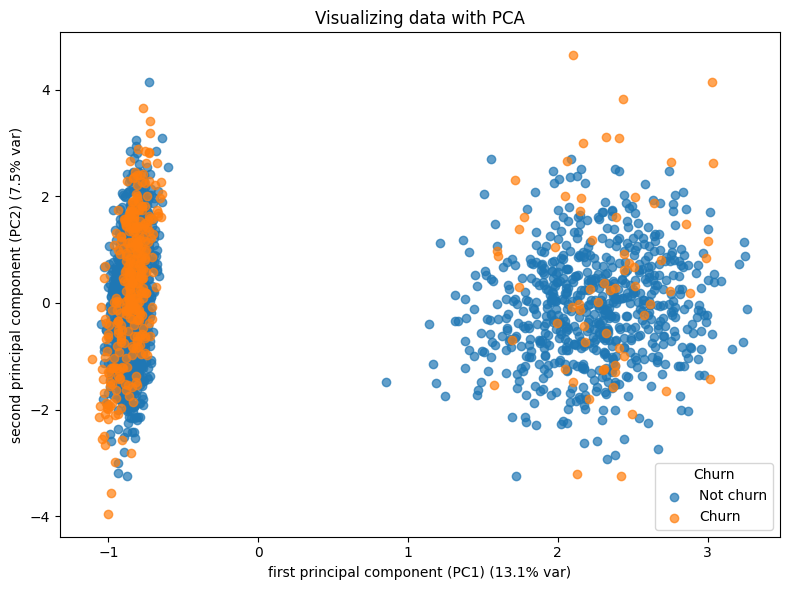

In [53]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

def pca_scatter_matplotlib(pcadf, targetfeature, label, ax):
    sub = pcadf[pcadf[targetfeature] == label]
    ax.scatter(sub["PC1"], sub["PC2"], label=str(label), alpha=0.7)

# ---- PCA ----
# IMPORTANT: target_col should be a string like "Churn" (not ["Churn"])
target_col = "Churn"

X = df_train.drop(columns=['Churn'])
Y = df_train['Churn']

pca = PCA(n_components=2, random_state=42)
principal_components = pca.fit_transform(X)

pca_data = pd.DataFrame(principal_components, columns=["PC1", "PC2"], index=df_train.index)
pca_data[target_col] = Y.values

# If churn is encoded 1/0, map to labels
pca_data[target_col] = pca_data[target_col].replace({1: "Churn", 0: "Not churn"})

# ---- Plot (matplotlib) ----
fig, ax = plt.subplots(figsize=(8, 6))

pca_scatter_matplotlib(pca_data, target_col, "Not churn", ax)
pca_scatter_matplotlib(pca_data, target_col, "Churn", ax)

expl = pca.explained_variance_ratio_
ax.set_title("Visualizing data with PCA")
ax.set_xlabel(f"first principal component (PC1) ({expl[0]:.1%} var)")
ax.set_ylabel(f"second principal component (PC2) ({expl[1]:.1%} var)")
ax.legend(title=target_col)

plt.tight_layout()
plt.show()


In [54]:
#export cleaned data
df_train.to_csv(OUTPUT / 'cleaned_train.csv', index=False)
df_test.to_csv(OUTPUT / 'cleaned_test.csv', index=False)
